# Taller 11: Máquinas de Soporte Vectorial con `digits`

Inteligencia Artificial (ELP 8012) — Universidad del Norte. Se busca el mejor kernel con k-fold (k=4, estratificado) y se compara con los talleres 9 y 10 usando la misma partición 80/20 (`random_state=42`).

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)

RANDOM_STATE = 42

## 1. Datos y partición

In [2]:
digits = load_digits()
X, y = digits.data, digits.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)

print(f"Observaciones: {X.shape[0]} | Atributos: {X.shape[1]} | Clases: {np.unique(y)}")
print(f"Entrenamiento: {len(X_train)} | Prueba: {len(X_test)} | Pliegues CV: {cv.n_splits}")

Observaciones: 1797 | Atributos: 64 | Clases: [0 1 2 3 4 5 6 7 8 9]
Entrenamiento: 1437 | Prueba: 360 | Pliegues CV: 4


## 2. Kernels con parámetros por defecto

Se usa `StandardScaler` dentro de un `Pipeline` para evitar fuga de información entre pliegues.

In [3]:
scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
}

def pipe_svm(**params):
    return Pipeline([("escala", StandardScaler()), ("svm", SVC(**params))])

filas = []
for kernel in ["linear", "poly", "rbf", "sigmoid"]:
    inicio = time.perf_counter()
    r = cross_validate(pipe_svm(kernel=kernel), X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    filas.append({
        "Kernel": kernel,
        "Accuracy CV": r["test_accuracy"].mean(),
        "Precision macro CV": r["test_precision_macro"].mean(),
        "Recall macro CV": r["test_recall_macro"].mean(),
        "F1 macro CV": r["test_f1_macro"].mean(),
        "Desv. F1 CV": r["test_f1_macro"].std(),
        "Segundos": time.perf_counter() - inicio,
    })

tabla_kernels = pd.DataFrame(filas).sort_values("F1 macro CV", ascending=False).reset_index(drop=True)
tabla_kernels.round(4)

,Kernel,Accuracy CV,Precision macro CV,Recall macro CV,F1 macro CV,Desv. F1 CV,Segundos
0,rbf,0.9812,0.9815,0.9811,0.9811,0.0094,0.2060
1,linear,0.9756,0.9763,0.9754,0.9754,0.0077,0.1480
2,poly,0.9457,0.9599,0.9459,0.9482,0.0053,0.2580
3,sigmoid,0.9436,0.9452,0.9435,0.9432,0.0025,0.1682


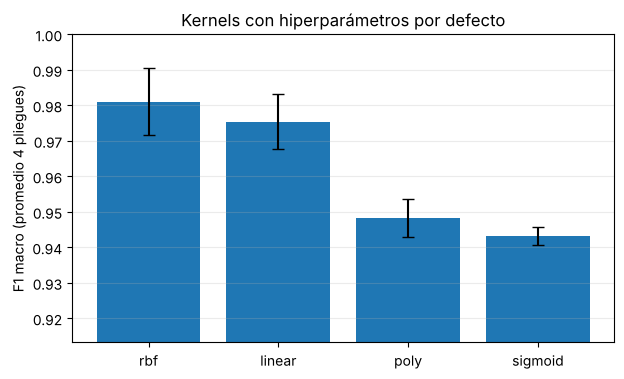

In [4]:
plt.figure(figsize=(7, 4))
plt.bar(tabla_kernels["Kernel"], tabla_kernels["F1 macro CV"],
        yerr=tabla_kernels["Desv. F1 CV"], capsize=4)
plt.ylim(tabla_kernels["F1 macro CV"].min() - 0.03, 1.0)
plt.ylabel("F1 macro (promedio 4 pliegues)")
plt.title("Kernels con hiperparámetros por defecto")
plt.grid(axis="y", alpha=0.25)
plt.show()

## 3. Ajuste de hiperparámetros por kernel (`GridSearchCV`, mismos 4 pliegues)

In [5]:
mallas = {
    "linear":  {"svm__C": [0.01, 0.1, 1, 10, 100]},
    "poly":    {"svm__C": [0.1, 1, 10, 100], "svm__degree": [2, 3, 4], "svm__gamma": ["scale", 0.001, 0.01]},
    "rbf":     {"svm__C": [0.1, 1, 10, 100], "svm__gamma": ["scale", 0.0001, 0.001, 0.01]},
    "sigmoid": {"svm__C": [0.1, 1, 10, 100], "svm__gamma": ["scale", 0.0001, 0.001, 0.01]},
}

mejores = {}
filas = []
for kernel, malla in mallas.items():
    gs = GridSearchCV(pipe_svm(kernel=kernel), malla, cv=cv, scoring="f1_macro", n_jobs=-1)
    gs.fit(X_train, y_train)
    mejores[kernel] = gs
    r = cross_validate(gs.best_estimator_, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    filas.append({
        "Kernel": kernel,
        "Mejores parámetros": {k.replace("svm__", ""): v for k, v in gs.best_params_.items()},
        "Accuracy CV": r["test_accuracy"].mean(),
        "Precision macro CV": r["test_precision_macro"].mean(),
        "Recall macro CV": r["test_recall_macro"].mean(),
        "F1 macro CV": r["test_f1_macro"].mean(),
        "Desv. F1 CV": r["test_f1_macro"].std(),
    })

tabla_tuned = pd.DataFrame(filas).sort_values("F1 macro CV", ascending=False).reset_index(drop=True)
pd.set_option("display.max_colwidth", None)
tabla_tuned.round(4)

,Kernel,Mejores parámetros,Accuracy CV,Precision macro CV,Recall macro CV,F1 macro CV,Desv. F1 CV
0,poly,"{'C': 100, 'degree': 3, 'gamma': 'scale'}",0.9833,0.9839,0.9833,0.9833,0.0046
1,rbf,"{'C': 10, 'gamma': 'scale'}",0.9819,0.9824,0.9818,0.9818,0.0058
2,linear,{'C': 0.1},0.9777,0.9786,0.9776,0.9777,0.0039
3,sigmoid,"{'C': 100, 'gamma': 0.001}",0.9777,0.9786,0.9776,0.9777,0.0039


In [6]:
mejor_kernel = tabla_tuned.loc[0, "Kernel"]
print(f"Mejor kernel según F1 macro promedio en validación cruzada: {mejor_kernel}")
print("Parámetros:", tabla_tuned.loc[0, "Mejores parámetros"])

Mejor kernel según F1 macro promedio en validación cruzada: poly
Parámetros: {'C': 100, 'degree': 3, 'gamma': 'scale'}


## 4. Efecto de `C` y `gamma`

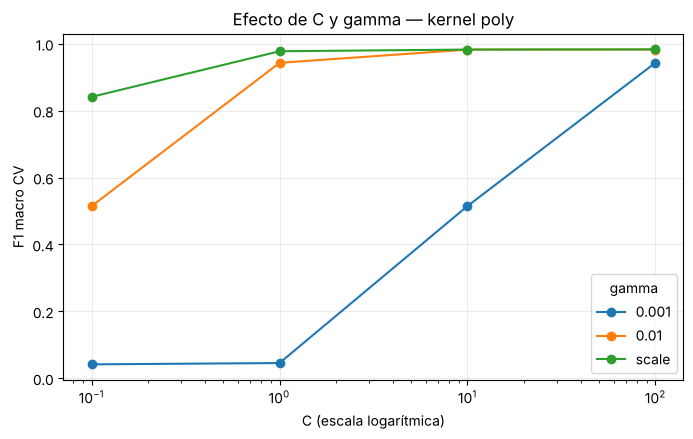

In [7]:
res = pd.DataFrame(mejores[mejor_kernel].cv_results_)
if "param_svm__gamma" in res.columns:
    res["gamma"] = res["param_svm__gamma"].astype(str)
    pivot = res.pivot_table(index="param_svm__C", columns="gamma",
                            values="mean_test_score", aggfunc="max")
    ax = pivot.plot(marker="o", figsize=(8, 4.5), logx=True)
    ax.set_xlabel("C (escala logarítmica)")
else:
    ax = res.set_index("param_svm__C")["mean_test_score"].plot(marker="o", figsize=(8, 4.5), logx=True)
    ax.set_xlabel("C (escala logarítmica)")
ax.set_ylabel("F1 macro CV")
ax.set_title(f"Efecto de C y gamma — kernel {mejor_kernel}")
ax.grid(alpha=0.25)
plt.show()

## 5. Evaluación final en prueba

In [8]:
filas = []
for kernel, gs in mejores.items():
    y_pred = gs.predict(X_test)
    filas.append({
        "Kernel": kernel,
        "Accuracy test": accuracy_score(y_test, y_pred),
        "Precision macro": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall macro": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1 macro": f1_score(y_test, y_pred, average="macro", zero_division=0),
    })
tabla_test = pd.DataFrame(filas).sort_values("F1 macro", ascending=False).reset_index(drop=True)
tabla_test.round(4)

,Kernel,Accuracy test,Precision macro,Recall macro,F1 macro
0,poly,0.9944,0.9945,0.9944,0.9944
1,linear,0.9833,0.9834,0.9831,0.9831
2,sigmoid,0.9833,0.9834,0.9831,0.9831
3,rbf,0.9806,0.9811,0.9804,0.9805


Reporte de clasificación — SVM kernel poly
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        36
           1     1.0000    1.0000    1.0000        36
           2     1.0000    1.0000    1.0000        35
           3     1.0000    1.0000    1.0000        37
           4     1.0000    1.0000    1.0000        36
           5     1.0000    1.0000    1.0000        37
           6     1.0000    0.9722    0.9859        36
           7     0.9730    1.0000    0.9863        36
           8     0.9722    1.0000    0.9859        35
           9     1.0000    0.9722    0.9859        36

    accuracy                         0.9944       360
   macro avg     0.9945    0.9944    0.9944       360
weighted avg     0.9946    0.9944    0.9944       360



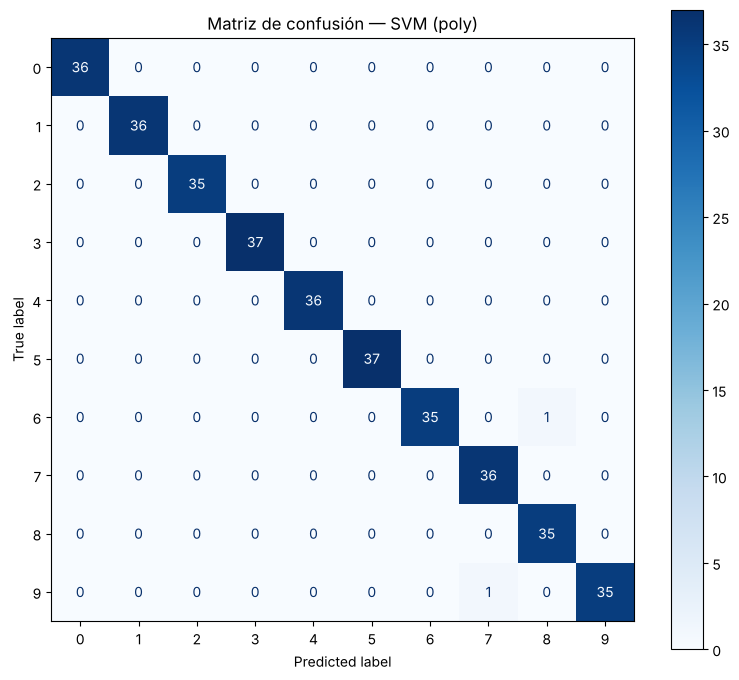

In [9]:
modelo_final = mejores[mejor_kernel].best_estimator_
y_pred = modelo_final.predict(X_test)
print(f"Reporte de clasificación — SVM kernel {mejor_kernel}")
print(classification_report(y_test, y_pred, digits=4, zero_division=0))

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues", values_format="d", ax=ax)
ax.set_title(f"Matriz de confusión — SVM ({mejor_kernel})")
plt.tight_layout()
plt.show()

## 6. Comparación con los talleres 9 y 10

Se reentrenan los mejores modelos anteriores (Naive Bayes `alpha=0.5` y MLP 64 neuronas `relu`) con la misma partición y los mismos pliegues.

In [10]:
modelos = {
    "Taller 9 — MultinomialNB (alpha=0.5)": MultinomialNB(alpha=0.5),
    "Taller 10 — MLP (64, relu)": Pipeline([
        ("escala", StandardScaler()),
        ("mlp", MLPClassifier(hidden_layer_sizes=(64,), activation="relu",
                              solver="lbfgs", max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    f"Taller 11 — SVM ({mejor_kernel})": modelo_final,
}

filas = []
for nombre, modelo in modelos.items():
    r = cross_validate(modelo, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    inicio = time.perf_counter()
    modelo.fit(X_train, y_train)
    seg = time.perf_counter() - inicio
    y_pred = modelo.predict(X_test)
    filas.append({
        "Modelo": nombre,
        "Accuracy CV": r["test_accuracy"].mean(),
        "F1 macro CV": r["test_f1_macro"].mean(),
        "Desv. F1 CV": r["test_f1_macro"].std(),
        "Accuracy test": accuracy_score(y_test, y_pred),
        "F1 macro test": f1_score(y_test, y_pred, average="macro"),
        "Segundos entrenamiento": seg,
    })

comparacion = pd.DataFrame(filas).set_index("Modelo")
comparacion.round(4)

,Accuracy CV,F1 macro CV,Desv. F1 CV,Accuracy test,F1 macro test,Segundos entrenamiento
Modelo,,,,,,
Taller 9 — MultinomialNB (alpha=0.5),0.9047,0.9050,0.0117,0.8889,0.8871,0.0018
"Taller 10 — MLP (64, relu)",0.9701,0.9700,0.0041,0.9806,0.9804,0.0535
Taller 11 — SVM (poly),0.9833,0.9833,0.0046,0.9944,0.9944,0.0642


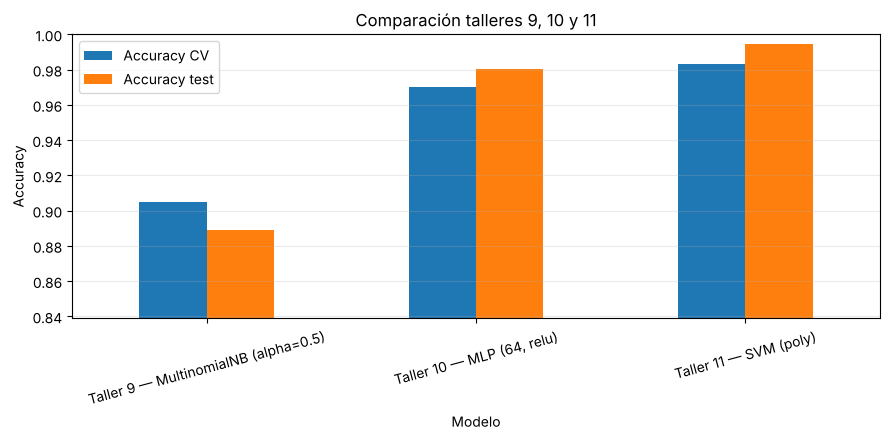

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.5))
comparacion[["Accuracy CV", "Accuracy test"]].plot.bar(ax=ax, rot=15)
ax.set_ylim(comparacion[["Accuracy CV", "Accuracy test"]].min().min() - 0.05, 1.0)
ax.set_ylabel("Accuracy")
ax.set_title("Comparación talleres 9, 10 y 11")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

In [12]:
acc = {n: [] for n in modelos}
for semilla in range(10):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=semilla)
    for nombre, modelo in modelos.items():
        from sklearn.base import clone
        m = clone(modelo).fit(Xtr, ytr)
        acc[nombre].append(accuracy_score(yte, m.predict(Xte)))

estabilidad = pd.DataFrame({
    "Accuracy media (10 particiones)": {n: np.mean(v) for n, v in acc.items()},
    "Desviación": {n: np.std(v, ddof=1) for n, v in acc.items()},
})
estabilidad.round(4)

,Accuracy media (10 particiones),Desviación
Taller 9 — MultinomialNB (alpha=0.5),0.9017,0.0134
"Taller 10 — MLP (64, relu)",0.9761,0.0085
Taller 11 — SVM (poly),0.9869,0.0045


## Conclusiones

- Con parámetros por defecto ganó `rbf`; tras el ajuste, el mejor kernel fue `poly` (grado 3, `C=100`): F1 macro CV ≈ 0.983 y accuracy en prueba ≈ 0.994. La diferencia con `rbf` (0.982) es menor que la desviación entre pliegues.
- Comparación (misma partición y pliegues):

| Modelo | Accuracy CV | Accuracy test | Media 10 particiones |
|---|---|---|---|
| Taller 9, Naive Bayes | 0.9047 | 0.8889 | 0.9017 |
| Taller 10, MLP relu | 0.9701 | 0.9806 | 0.9761 |
| Taller 11, SVM poly | 0.9833 | 0.9944 | 0.9869 |

- La SVM supera a Naive Bayes y a la red neuronal, y es la más estable entre particiones. Los hiperparámetros se eligieron con la semilla 42, por lo que el promedio de 10 particiones puede ser levemente optimista.